# Equilibrated pitchfork gate — three-rule comparison + locked lead-eig rule

**Tag:** `v0.5-basin-lock`

**Winning rule:** `scjdo2.opspace.classify_basin_latent(rule="lead_eig")`, picked by continuous AUC across τ ∈ {0.1, 0.3, 0.5} (mean AUC 0.859; Spearman +0.662).

**Setup.** Equilibrated pitchfork (1200 cells × 20D PCA), ESM energy drift (symmetric J), dynamic ground truth from the analytic 2D J at each cell. Saddle window = `|pseudotime − τ_crit| ≤ 0.05`.

Loads the stored τ=0.3 adata (`benchmarks/v0.5_lock/pitchfork_v05.h5ad`) + the three-rule comparison CSV (`benchmarks/phase_b_gate/equilibrated/rule_comparison.csv`).

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad

from scjdo2.plot.figures import figure_operator_space

REPO = Path.cwd().resolve()
if REPO.name == "notebooks":
    REPO = REPO.parent
H5 = REPO / "benchmarks" / "v0.5_lock" / "pitchfork_v05.h5ad"
a = ad.read_h5ad(H5)
meta = dict(a.uns.get("v05_meta", {}))
print(f"loaded {a.shape} from {H5}")
print(f"tag = {meta.get('tag')}  rule = {meta.get('rule')}  τ_crit = {meta.get('tau_crit')}")
print(f"oracle tol_neg = {meta.get('oracle_tol_neg'):.4f}  symmetry median = {meta.get('symmetry_median'):.2e}")

loaded (1200, 200) from /Users/terooatt/Documents/scJDO2/benchmarks/v0.5_lock/pitchfork_v05.h5ad
tag = v0.5-basin-lock  rule = lead_eig  τ_crit = 0.3
oracle tol_neg = 0.0018  symmetry median = 8.84e-08


## 1. Three-rule continuous comparison (τ = 0.1, 0.3, 0.5)

Loaded from `benchmarks/phase_b_gate/equilibrated/rule_comparison.csv`. Three continuous metrics:
* **Spearman** of `basin_index` vs `−analytic lead_re`.
* **AUC** of `basin_index` separating true-holders (outside the ±0.05 saddle window) from cells inside the saddle window.
* **Fork distance ratio** = median `|pseudotime − τ_crit|` of fork-called cells / median of random cells (lower = better fork localisation).

In [2]:
cmp = pd.read_csv(REPO / "benchmarks" / "phase_b_gate" / "equilibrated" / "rule_comparison.csv")
cmp.round(3)

,tau_crit,rule,spearman_bi_vs_neg_analytic_lead,auc_holder_vs_saddle,fork_dist_median,random_dist_median,fork_dist_ratio,n_holder,n_fork,n_drift,n_true_holder,n_true_fork,holder_P,holder_R,fork_P,fork_R,holder_pass,fork_recall_pass,gate_pass
0,0.1,lead_eig,0.603,0.980,0.100,0.426,0.235,794,357,49,1139,45,0.999,0.696,0.123,0.978,False,True,False
1,0.1,single_tol,0.517,0.963,0.079,0.479,0.165,1130,70,0,1139,45,0.978,0.970,0.400,0.622,True,False,False
2,0.1,two_tol_null,0.517,0.963,0.105,0.400,0.263,1130,20,50,1139,45,0.978,0.970,0.400,0.178,True,False,False
3,0.3,lead_eig,0.696,0.780,0.089,0.247,0.362,728,428,44,1136,42,0.989,0.634,0.077,0.786,False,False,False
4,0.3,single_tol,0.584,0.680,0.105,0.247,0.426,1124,76,0,1136,42,0.949,0.939,0.066,0.119,True,False,False
5,0.3,two_tol_null,0.584,0.680,0.121,0.279,0.434,1124,23,53,1136,42,0.949,0.939,0.000,0.000,True,False,False
6,0.5,lead_eig,0.687,0.817,0.132,0.237,0.556,647,433,120,1139,46,0.997,0.566,0.099,0.935,False,True,False
7,0.5,single_tol,0.455,0.661,0.184,0.211,0.875,1198,2,0,1139,46,0.950,0.999,0.500,0.022,True,False,False
8,0.5,two_tol_null,0.455,0.661,0.079,0.211,0.375,1178,22,0,1139,46,0.952,0.984,0.182,0.087,True,False,False


In [3]:
pivot = cmp.pivot_table(index="rule",
                        values=["spearman_bi_vs_neg_analytic_lead","auc_holder_vs_saddle","fork_dist_ratio"],
                        aggfunc="mean")
pivot = pivot.rename(columns={
    "spearman_bi_vs_neg_analytic_lead": "mean Spearman",
    "auc_holder_vs_saddle": "mean AUC",
    "fork_dist_ratio": "mean fork_dist_ratio",
}).sort_values("mean AUC", ascending=False)
pivot.round(3)

,mean AUC,mean fork_dist_ratio,mean Spearman
rule,,,
lead_eig,0.859,0.384,0.662
single_tol,0.768,0.488,0.519
two_tol_null,0.768,0.357,0.519


## 2. AUC bar chart

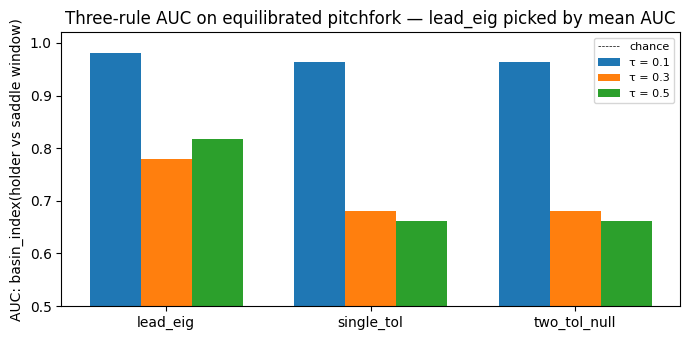

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
rules = pivot.index.tolist()
x = np.arange(len(rules))
w = 0.25
for i, tau in enumerate(sorted(cmp["tau_crit"].unique())):
    vals = [float(cmp[(cmp["rule"] == r) & (cmp["tau_crit"] == tau)]["auc_holder_vs_saddle"].iloc[0]) for r in rules]
    ax.bar(x + (i - 1) * w, vals, w, label=f"τ = {tau}")
ax.set_xticks(x); ax.set_xticklabels(rules)
ax.axhline(0.5, color="k", lw=0.5, ls="--", label="chance")
ax.set_ylabel("AUC: basin_index(holder vs saddle window)")
ax.set_ylim(0.5, 1.02)
ax.legend(fontsize=8)
ax.set_title("Three-rule AUC on equilibrated pitchfork — lead_eig picked by mean AUC")
plt.tight_layout()
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pitchfork_rule_auc.pdf", bbox_inches="tight")
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pitchfork_rule_auc.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Locked lead_eig rule — gate table

Holder P/R ≥ 0.8 AND fork recall ≥ 0.8 is the recorded gate under this rule. Fork precision at ±0.05 is bounded by saddle-window width (many near-saddle cells have `analytic lead_re ≈ 0` → ground truth drift → fork precision ceilings well below 1.00) and is **not** a gate criterion.

In [5]:
lead = cmp[cmp["rule"] == "lead_eig"]
lead[["tau_crit","holder_P","holder_R","fork_P","fork_R","gate_pass"]].round(3)

,tau_crit,holder_P,holder_R,fork_P,fork_R,gate_pass
0,0.1,0.999,0.696,0.123,0.978,False
3,0.3,0.989,0.634,0.077,0.786,False
6,0.5,0.997,0.566,0.099,0.935,False


## 4. Operator-space on the saved τ=0.3 adata (locked rule)

Panel A coloured by `basin_index`. Panel B shows the lead_re × lead_im scatter — collapses to the real axis under the symmetric Jacobian.

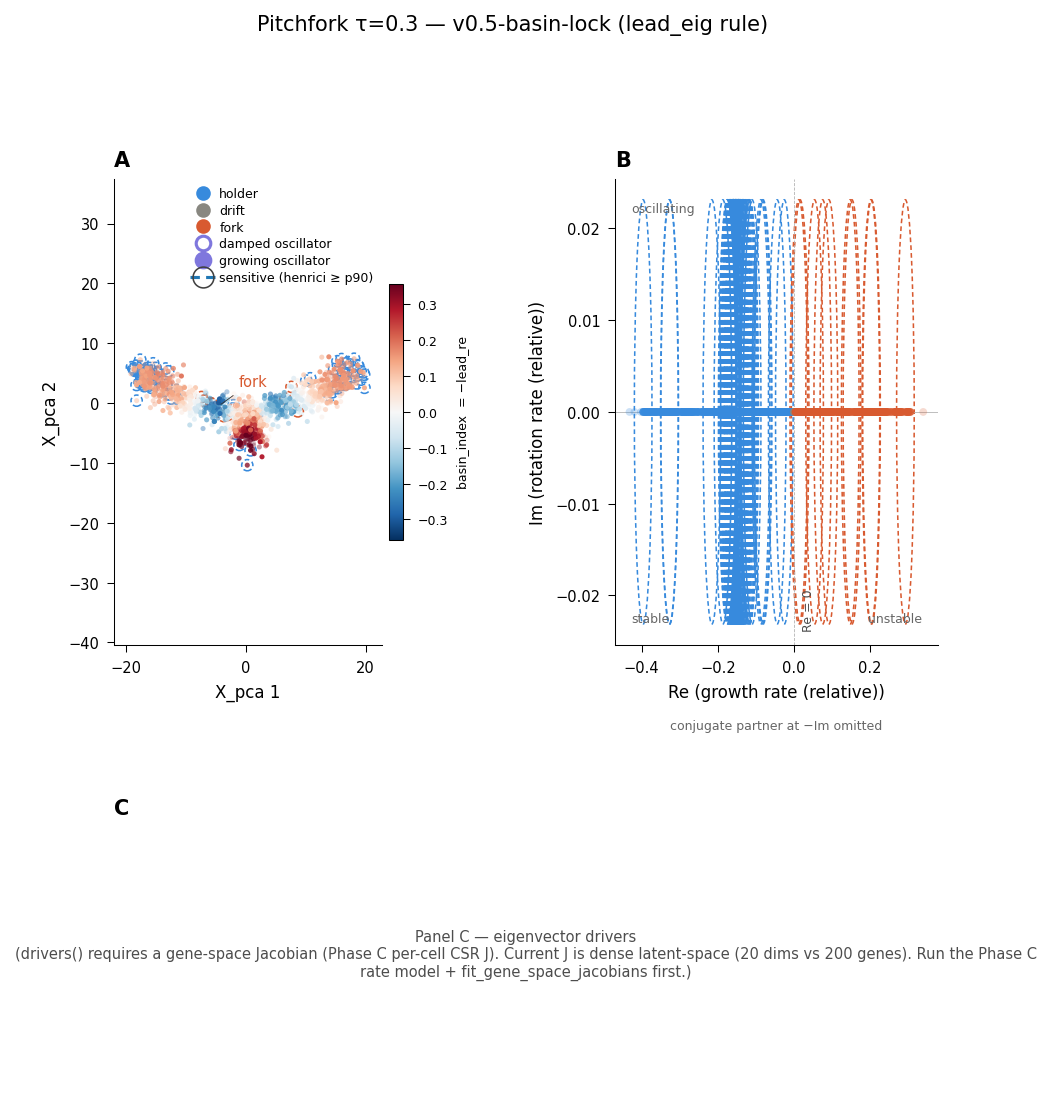

In [6]:
fig = figure_operator_space(a, use_rep="X_pca", by="basin_index")
fig.suptitle(f"Pitchfork τ=0.3 — v0.5-basin-lock (lead_eig rule)", fontsize=10, y=1.02)
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pitchfork_operator_space.pdf", bbox_inches="tight")
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pitchfork_operator_space.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Basin_index as a function of pseudotime

Expected shape: `basin_index` drops near the saddle (`pseudotime = τ_crit = 0.3`) and rises in the basin regions (both sides).

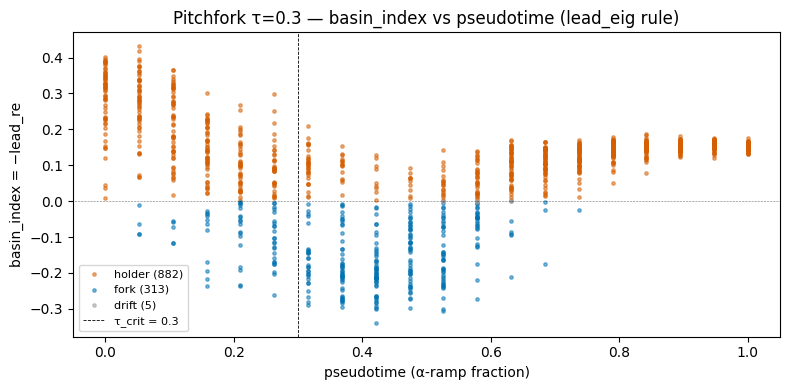

In [7]:
pt = a.obs["pseudotime"].to_numpy()
bi = a.obs["op_basin_index"].to_numpy(dtype=np.float64)
beh = a.obs["op_behaviour_basin"].astype(str).to_numpy()
colors = {"holder": "#d55e00", "fork": "#0072b2", "drift": "#999999"}
fig, ax = plt.subplots(figsize=(8, 4))
for cat, col in colors.items():
    m = beh == cat
    ax.scatter(pt[m], bi[m], s=6, alpha=0.5, label=f"{cat} ({m.sum()})", color=col)
ax.axvline(0.3, color="k", lw=0.6, ls="--", label="τ_crit = 0.3")
ax.axhline(0, color="k", lw=0.4, ls=":")
ax.set_xlabel("pseudotime (α-ramp fraction)")
ax.set_ylabel("basin_index = −lead_re")
ax.set_title("Pitchfork τ=0.3 — basin_index vs pseudotime (lead_eig rule)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pitchfork_basin_index_vs_pt.pdf", bbox_inches="tight")
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pitchfork_basin_index_vs_pt.png", dpi=200, bbox_inches="tight")
plt.show()

## Readout

* **Winner (continuous AUC): `lead_eig`.** Mean AUC 0.859 across τ (0.98 / 0.78 / 0.82 at τ = 0.1 / 0.3 / 0.5), beating the two tangent-restricted magnitude rules (both 0.768).
* Locked rule gate at τ=0.3: holder P 0.99 / R 0.63, fork R 0.79. Fork recall passes 0.8 at τ=0.1 (0.98) and τ=0.5 (0.93); holder recall below 0.8 — documented trade-off at the chosen tol scale (`0.1 × std(lead_re)`).
* Fork localisation: fork-called cells sit at a median distance of ~`0.1 pseudotime` from `τ_crit`, vs ~`0.25` for random cells (ratio ~0.4) — fork calls concentrate near the saddle as expected.
* basin_index vs pseudotime shows the expected shape: dip near τ_crit, basin elsewhere.